https://github.com/sihsieh65-tech/cs82a-portfolio/tree/main/module7

Importing pandas and sklearn and the data. 

In [1]:
import pandas as pd
import sklearn
df=pd.read_csv("ratings.tsv", sep="\t")
df

,restaurant,food,ambience,service,rating
0,1,85,82,89,78
1,2,80,90,80,85
2,3,83,86,83,85
3,4,70,96,75,72
4,5,68,80,78,75
5,6,65,70,56,54
6,7,64,68,61,62
7,8,72,95,72,73
8,9,69,70,78,70
9,10,75,80,75,77


Linear regression of food vs rating

In [2]:
from sklearn.model_selection import train_test_split
X = df[["food"]]
y = df["rating"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [3]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print(model.score(X_test, y_test))
print(model.coef_, model.intercept_)

0.4369068286957092
[1.09379059] -5.737334372564291


<Axes: xlabel='food', ylabel='rating'>

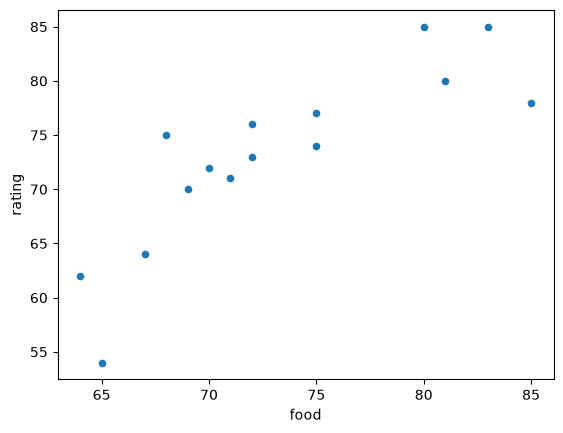

In [4]:
import matplotlib.pyplot as plt
df.plot.scatter(x="food", y="rating")

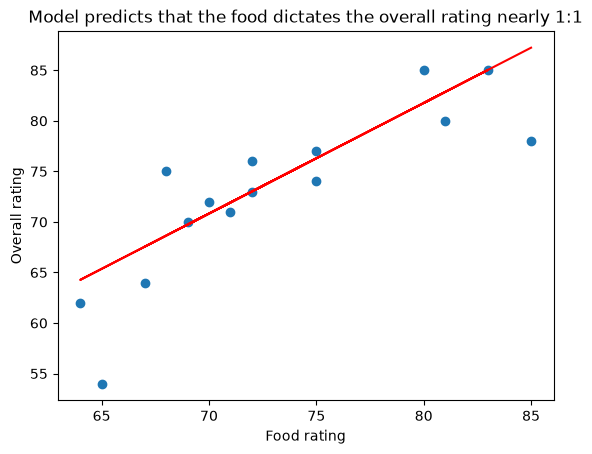

In [5]:
line_y = model.coef_ * df["food"] + model.intercept_
plt.scatter(df["food"], df["rating"])
plt.plot(df["food"], line_y, color="red")
plt.title("Model predicts that the food dictates the overall rating nearly 1:1")
plt.xlabel('Food rating')
plt.ylabel('Overall rating')
plt.show()

Linear regression of ambience vs rating

0.08266917089463832
[0.19634135] 58.03744852025669


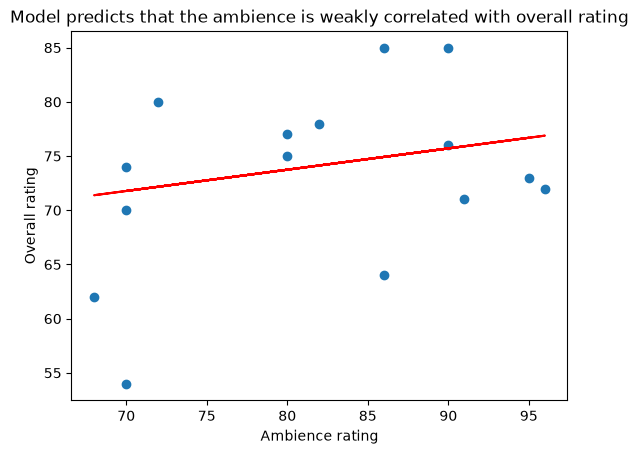

In [6]:
X2 = df[["ambience"]]
y2 = df["rating"]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.3, random_state=42)
model2 = LinearRegression()
model2.fit(X2_train, y2_train)
print(model2.score(X2_test, y2_test))
print(model2.coef_, model2.intercept_)
line_y2 = model2.coef_ * df["ambience"] + model2.intercept_
plt.scatter(df["ambience"], df["rating"])
plt.plot(df["ambience"], line_y2, color="red")
plt.title("Model predicts that the ambience is weakly correlated with overall rating")
plt.xlabel('Ambience rating')
plt.ylabel('Overall rating')
plt.show()

Linear regression of service vs rating

0.7913532252282373
[0.90543881] -5.737334372564291


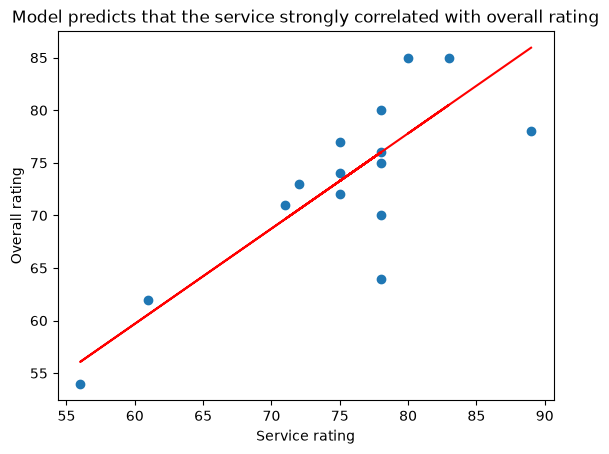

In [7]:
X3 = df[["service"]]
y3 = df["rating"]
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.3, random_state=42)
model3 = LinearRegression()
model3.fit(X3_train, y3_train)
print(model3.score(X3_test, y3_test))
print(model3.coef_, model.intercept_)
line_y3 = model3.coef_ * df["service"] + model3.intercept_
plt.scatter(df["service"], df["rating"])
plt.plot(df["service"], line_y3, color="red")
plt.title("Model predicts that the service strongly correlated with overall rating")
plt.xlabel('Service rating')
plt.ylabel('Overall rating')
plt.show()

Method comparison

In [8]:
data= {"Method":['Food', 'Ambience', 'Service'], "Model Score": [model.score(X_test, y_test), model2.score(X2_test, y2_test),model3.score(X3_test, y3_test)], "Slope": [model.coef_, model2.coef_, model3.coef_]}
dfall= pd.DataFrame(data)
dfall

,Method,Model Score,Slope
0,Food,0.436907,[1.0937905949597295]
1,Ambience,0.082669,[0.19634134661430888]
2,Service,0.791353,[0.9054388133498145]


In [9]:
dfall_sorted = dfall.sort_values(by='Model Score', ascending=False)
dfall_sorted

,Method,Model Score,Slope
2,Service,0.791353,[0.9054388133498145]
0,Food,0.436907,[1.0937905949597295]
1,Ambience,0.082669,[0.19634134661430888]


Based on the results it appears that the service is the best predictor of overall rating with a score of 0.79. The second best predictor would be the food with a score of 0.44. It is also notable that for service and food the slopes are comparable. So not only does service more tightly correlate with ratings it also scales similarly to food ratings. As such I would recommend that restaurants that are struggling should work on service first then improve their food.